**ANOMALY DETECTION OC-SVM**

In [1]:
import digitalhub as dh
import zipfile
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


**SETUP PARAMETERS**

In [2]:


parameters = {
    "job_name": "probe_v1_vs_v2",
    "results_artifacts": ["anomaly_results_md_net_v3_0per_v2", "anomaly_results_md_attn_0per"],
    "include_normals": True,
    "n_folds": 5,
    "seed": 0,
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "200Gi"}
    }
]

**BUILD ENVIRONMENT**

In [ ]:
ocsvm_func = project.new_function(
    name=f'linear',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../src/",
    handler="anomaly:linear_probe",
    image="harbor.atlas.fbk.eu/rsde/rsde-platform-floods-floodsimagev3:9b7e2",
)

**TRAINING**

In [4]:
resources = {"cpu": "4", "mem": "20Gi"}

run_ad = ocsvm_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    resources = resources,
    profile="1xv100-shared",
    local_execution=False,
    wait=True
)

print(f"Run anomaly detection ocsvm: {run_ad.id}")

2026-10-23 14:41:06,025 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 788ba96597f740fa834eee57a5d22d5c to finish...
2026-10-23 14:41:11,032 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 788ba96597f740fa834eee57a5d22d5c to finish...
2026-10-23 14:41:16,041 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 788ba96597f740fa834eee57a5d22d5c to finish...
2026-10-23 14:41:21,050 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 788ba96597f740fa834eee57a5d22d5c to finish...
2026-10-23 14:41:26,058 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 788ba96597f740fa834eee57a5d22d5c to finish...
2026-10-23 14:41:31,129 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 788ba96597f740fa834eee57a5d22d5c to finish...
2026-10-23 14:41:36,140 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 788ba96597f740fa834eee57a5d22d5c to finish...
2026-10-23 14

Run anomaly detection ocsvm: 788ba96597f740fa834eee57a5d22d5c


In [5]:
RESULTS_DIR = "/tmp/anomaly_results_ocsvm"

zip_path = project.get_artifact(f"anomaly_results_ocsvm_{job_name}").download("/tmp/anomaly_results_ocsvm.zip", overwrite=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(RESULTS_DIR)
with open(f"{RESULTS_DIR}/anomaly_results.json") as f:
    results = json.load(f)

df = pd.read_csv(f"{RESULTS_DIR}/scores.csv")                    
score_normal = df[df.label == 0]['score']
score_anom = df[df.label == 1]['score']

print(f"n_fit: {results['n_fit']} | n_thr: {results['n_thr']} | n_normali: {results['n_normali']} | n_anomale: {results['n_anomale']}", "\n")
print(f"nu: {results['ocsvm']['nu']} | gamma: {results['ocsvm']['gamma']} | dim: {results['ocsvm']['dim']} | frac_outside_fit: {results['ocsvm']['frac_outside_fit']}") 
print(f"min_flood_area = {results['min_flood_area']:.3f} ")
print(f"score normali: {score_normal.mean():.4f} ± {score_normal.std():.4f}")
print(f"score anomale: {score_anom.mean():.4f} ± {score_anom.std():.4f}", "\n")
print(f"AUROC: {results['auroc']:.3f}")

df_rules = pd.DataFrame(results['rules']).T
df_rules

NameError: name 'job_name' is not defined

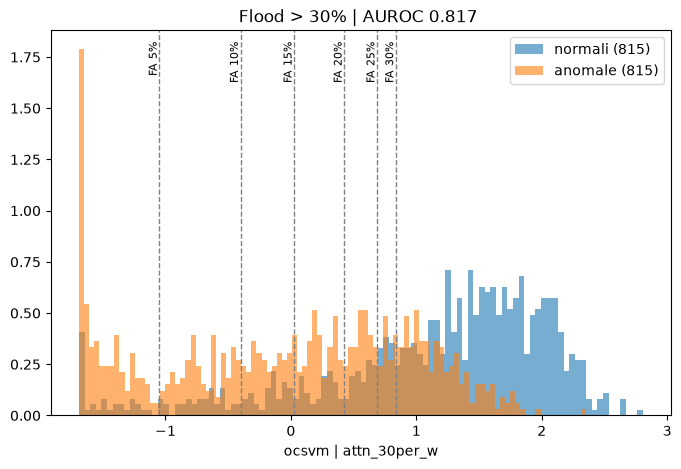

In [ ]:
df = pd.read_csv(f"{RESULTS_DIR}/scores.csv")
score_normal = df[df.label == 0]['score']
score_anom = df[df.label == 1]['score']

lo, hi = np.quantile(df.score, [0.005, 0.995])                   
bins = np.linspace(lo, hi, 100)

plt.figure(figsize=(8, 5))
plt.hist(score_normal, bins=100, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
plt.hist(score_anom, bins=100, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")
for nome, r in results['rules'].items():                         
    if lo <= r["soglia"] <= hi:
        plt.axvline(x=r["soglia"], color='gray', linestyle='--', linewidth=1)
        plt.text(r["soglia"], plt.ylim()[1] * 0.97, nome.split("(")[-1].rstrip(")"), rotation=90, va="top", ha="right", fontsize=8)   
plt.xlabel(f"ocsvm | {job_name}")
plt.legend()
plt.title(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f} ")
plt.show()

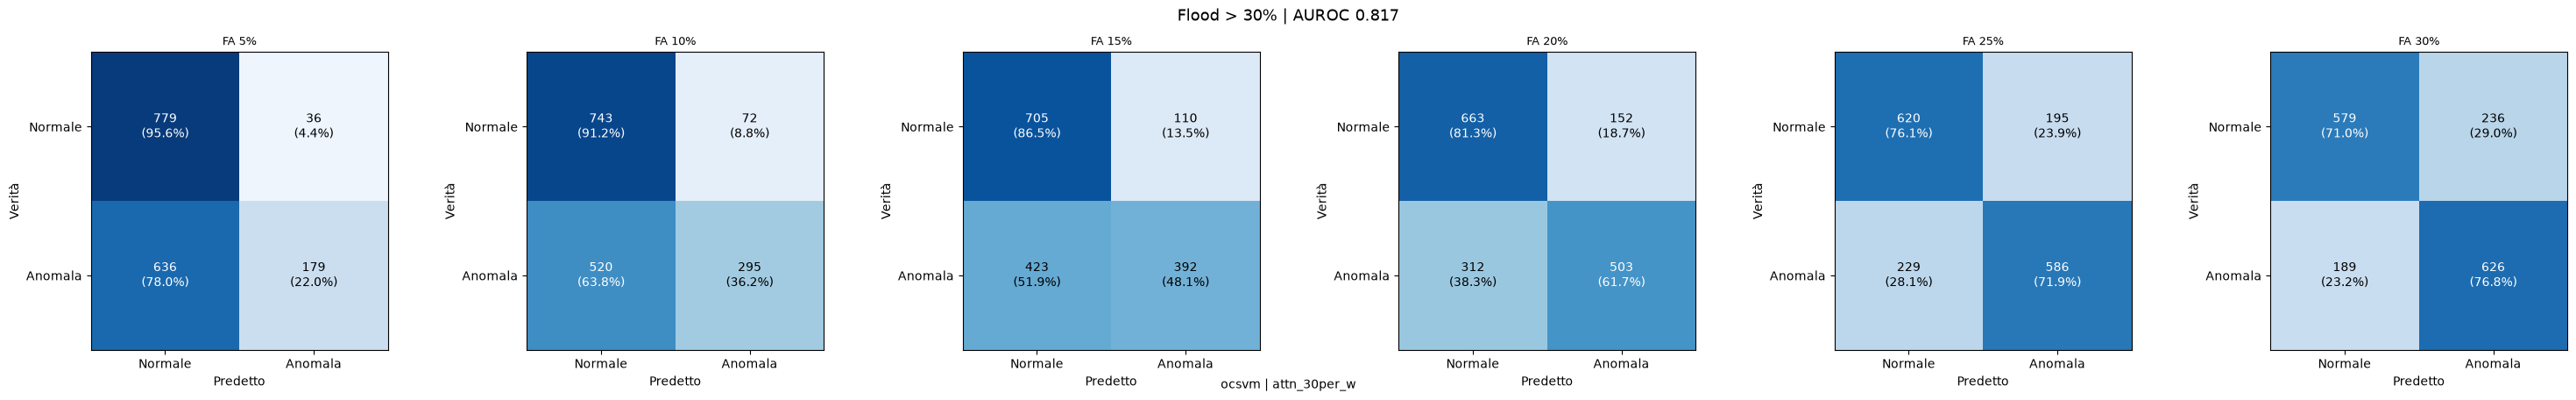

In [ ]:
rules = results['rules']
fig, axes = plt.subplots(1, len(rules), figsize=(5 * len(rules), 4.5), squeeze=False)

for ax, (nome, r) in zip(axes[0], rules.items()):
    mat = np.array([[r["TN"], r["FP"]],
                     [r["FN"], r["TP"]]])
    mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

    im = ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
    ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
    ax.set_title(nome, fontsize=9)

    for i in range(2):
        for j in range(2):
            color = "white" if mat_pct[i, j] > 55 else "black"
            ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                    ha="center", va="center", color=color, fontsize=10)

fig.suptitle(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}", fontsize=13)
fig.text(0.5, 0.01, f"ocsvm | {job_name}", ha="center", va="bottom", fontsize=10)              

plt.tight_layout()
plt.show()